# 02 — Préparation des données : découpage, mise à l'échelle, patches

Ce notebook prépare une fois pour toutes les données utilisées par les trois objectifs. Toutes les
décisions prises ici sont réutilisées telles quelles par les notebooks 03 à 05.

### Étapes de ce notebook

1. Importer les bibliothèques
2. Découper en entraînement / validation / test (40 / 10 / 10)
3. Mettre les images à la résolution de travail (512 × 288) et les mettre en cache
4. Calculer le poids des pixels d'obstacle (déséquilibre)
5. Vérifier l'augmentation de données
6. Découper les images en zones de 96 × 96 pour BO1
7. Sauvegarder les choix de préparation

> Tous les chiffres, tableaux et figures de ce notebook sont produits par son exécution sur le jeu
> RoadAnomaly ; aucun résultat n'est écrit à la main.

## 0. Préparer l'environnement

On vérifie le GPU, on localise le dossier du projet (Colab ou local), on charge la configuration commune
(graine 42, résolution de travail 512 × 288) et on télécharge RoadAnomaly s'il est absent.

In [1]:
# Vérification du GPU (Colab : Exécution > Modifier le type d'exécution > GPU T4)
!nvidia-smi || echo "Pas de GPU visible : les entraînements seront très lents."

Thu Nov  5 15:11:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   62C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os, sys
IN_COLAB = 'google.colab' in sys.modules
USE_DRIVE = True   # False : travail dans /content (fichiers perdus à la fin de la session)
# Mode test rapide (activé par 00_main.ipynb) : 2 époques par modèle, sorties dans outputs_quick/.
# Sert uniquement à vérifier que la chaîne s'exécute ; ses chiffres ne doivent jamais être rapportés.
QUICK = os.environ.get('RA_QUICK') == '1'
EP = lambda n: 2 if QUICK else n

if os.environ.get('RA_PROJECT_DIR'):            # exécution pilotée par 00_main.ipynb (Drive déjà monté)
    PROJECT_DIR = os.environ['RA_PROJECT_DIR']
elif IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/RoadAnomaly_BO_Project'
elif IN_COLAB:
    PROJECT_DIR = '/content/RoadAnomaly_BO_Project'
else:
    PROJECT_DIR = os.path.abspath('..')        # exécution locale depuis notebooks/
DATA_DIR = os.path.join(PROJECT_DIR, 'data')   # contient (ou contiendra) RoadAnomaly/

# Si seul l'archive du projet a été déposée, on la décompresse
zip_path = PROJECT_DIR + '.zip'
if not os.path.isdir(os.path.join(PROJECT_DIR, 'src')) and os.path.isfile(zip_path):
    import zipfile
    zipfile.ZipFile(zip_path).extractall(os.path.dirname(PROJECT_DIR))
assert os.path.isdir(os.path.join(PROJECT_DIR, 'src')), \
    f"src/ introuvable dans {PROJECT_DIR} : copiez le dossier du projet à cet endroit."
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

from src.config import ProjectPaths, TrainConfig, set_seed, environment_report, save_json, load_json
paths = ProjectPaths(PROJECT_DIR, DATA_DIR, outputs_name='outputs_quick' if QUICK else 'outputs')
cfg = TrainConfig()
set_seed(cfg.seed)
W, H = cfg.work_size
FIG, RES, PREDS, EXPORT = paths.sub('figures'), paths.sub('results'), paths.sub('preds'), paths.sub('webapp_models')
ENV = environment_report()
print(ENV)
if QUICK:
    print('*** MODE TEST RAPIDE : résultats NON valides, écrits dans', paths.outputs, '***')

{'python': '3.13.16', 'numpy': '2.4.6', 'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'sklearn': '1.6.1', 'PIL': '11.3.0', 'gradio': '6.31.0', 'cuda': '13.0', 'gpu': 'Tesla T4'}


In [3]:
from src.dataset import ensure_dataset, list_frames
ROOT = ensure_dataset(DATA_DIR)        # télécharge et décompresse le dataset si absent
print('Dataset :', ROOT)

Dataset : /content/RoadAnomaly_BO_Project/data/RoadAnomaly


## 1. Importer les bibliothèques

In [4]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.dataset import make_splits, check_no_leakage, load_arrays, family_of, augment_pair, extract_patches
from src.visualize import overlay

## 2. Découper en entraînement / validation / test

- **Entraînement (40 images)** : les modèles apprennent dessus.
- **Validation (10 images)** : sert à choisir le meilleur état de chaque modèle, son seuil de décision et
  le meilleur modèle de chaque BO.
- **Test (10 images)** : n'est regardé qu'à la fin, pour mesurer les performances.

Le découpage est stratifié par catégorie (chaque catégorie est représentée partout) et groupé par scène :
les images d'une même scène restent toutes en entraînement, pour qu'aucune scène du test n'ait été vue.

In [5]:
names = list_frames(ROOT)
splits = make_splits(names, n_val=10, n_test=10, seed=cfg.seed)
check_no_leakage(splits)
save_json(splits, os.path.join(paths.sub('splits'), 'splits.json'))
rows = [(s, family_of(n)) for s, lst in splits.items() for n in lst]
display(pd.crosstab(pd.Series([f for _, f in rows], name='famille'),
                    pd.Series([s for s, _ in rows], name='split'), margins=True))

split,test,train,val,All
famille,,,,
autre,1,1,1,3
debris_objets_perdus,0,12,1,13
faune,6,19,6,31
infrastructure_temporaire,3,8,2,13
All,10,40,10,60


## 3. Mettre les images à la résolution de travail

Toutes les images et tous les masques sont ramenés à 512 × 288 (format 16:9, dimensions multiples de 32
comme l'exigent les encodeurs convolutifs) et enregistrés dans un fichier unique, relu par les notebooks
suivants.

In [6]:
arrays = {s: load_arrays(ROOT, lst, (W, H)) for s, lst in splits.items()}
np.savez_compressed(os.path.join(paths.sub('processed'), f'arrays_{W}x{H}.npz'),
                    **{f'{s}_images': a[0] for s, a in arrays.items()},
                    **{f'{s}_masks': a[1] for s, a in arrays.items()},
                    **{f'{s}_names': np.array(splits[s]) for s in arrays})
for s, (im, m) in arrays.items():
    print(f'{s:5s} images {im.shape}  pixels d\'obstacle {m.mean():.4f}')

train images (40, 288, 512, 3)  pixels d'obstacle 0.0879
val   images (10, 288, 512, 3)  pixels d'obstacle 0.1329
test  images (10, 288, 512, 3)  pixels d'obstacle 0.1064


## 4. Calculer le poids des pixels d'obstacle

Les obstacles couvrent une petite part des pixels. Sans correction, un modèle qui répond « fond »
partout aurait l'air bon. On donne donc plus de poids aux pixels d'obstacle dans la perte de BO2 :
poids = (part de fond) / (part d'obstacle), calculé sur l'entraînement seulement et plafonné à 10.

In [7]:
pos = float(arrays['train'][1].mean())
pos_weight = min((1 - pos) / pos, cfg.max_pos_weight)
print(f'part de pixels d\'obstacle (entraînement) = {pos:.4f} -> poids = {pos_weight:.2f} '
      f'(plafonné à {cfg.max_pos_weight})')

part de pixels d'obstacle (entraînement) = 0.0879 -> poids = 10.00 (plafonné à 10.0)


## 5. Vérifier l'augmentation de données

Avec 40 images, on crée des variantes à chaque passage : miroir horizontal, zoom / recadrage, variation
de luminosité, de contraste et de couleur. Le masque subit la même transformation géométrique que l'image.

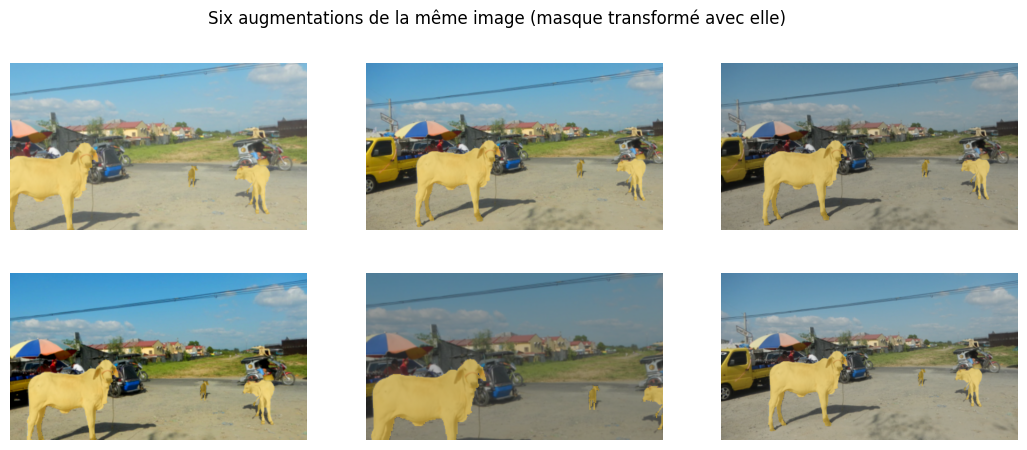

In [8]:
rng = np.random.default_rng(cfg.seed)
img, m = arrays['train'][0][0], arrays['train'][1][0]
fig, axes = plt.subplots(2, 3, figsize=(13, 5))
for ax in axes.ravel():
    a, b = augment_pair(img, m, rng)
    ax.imshow(overlay(a, b)); ax.axis('off')
fig.suptitle('Six augmentations de la même image (masque transformé avec elle)')
fig.savefig(os.path.join(FIG, '02_augmentations.png'), dpi=120); plt.show()

## 6. Découper les images en zones de 96 × 96 pour BO1

Toutes les images contiennent un obstacle : au niveau de l'image entière, il n'y aurait aucun exemple
« sans obstacle ». On découpe donc chaque image en zones de 96 × 96 pixels (pas de 48) :
- zone **avec obstacle** si au moins 5 % de ses pixels sont des pixels d'obstacle ;
- zone **sans obstacle** si elle n'en contient aucun ;
- les zones entre les deux (bords d'objets) sont écartées.

In [9]:
PATCH, STRIDE, POS_MIN = 96, 48, 0.05
patch_data, patch_meta = {}, {}
for s, (im, m) in arrays.items():
    X, y, meta = extract_patches(im, m, splits[s], patch=PATCH, stride=STRIDE, pos_min=POS_MIN)
    patch_data[f'X_{s}'], patch_data[f'y_{s}'] = X, y
    patch_meta[s] = meta
    print(f'{s:5s} zones {len(y):5d}  avec obstacle {int(y.sum()):4d}  sans obstacle {int((y == 0).sum()):4d}')
np.savez_compressed(os.path.join(paths.sub('processed'), f'patches_{PATCH}.npz'), **patch_data)
save_json(patch_meta, os.path.join(paths.sub('processed'), f'patches_{PATCH}_meta.json'))

train zones  1527  avec obstacle  624  sans obstacle  903
val   zones   413  avec obstacle  216  sans obstacle  197
test  zones   365  avec obstacle  150  sans obstacle  215


## 7. Sauvegarder les choix de préparation

In [10]:
save_json({'notebook': '02', 'env': ENV, 'config': cfg.to_dict(), 'split_sizes': {k: len(v) for k, v in splits.items()},
           'pixel_pos_fraction_train': pos, 'pos_weight': pos_weight,
           'patches': {'size': PATCH, 'stride': STRIDE, 'pos_min': POS_MIN,
                       **{s: {'n': int(len(patch_data[f'y_{s}'])), 'pos': int(patch_data[f'y_{s}'].sum())}
                          for s in arrays}}},
          os.path.join(RES, '02_preprocessing.json'))

## Conclusion (rédigée à partir des sorties ci-dessus, exécution du 05/11/2026)

- **Découpage** : entraînement 40 images (faune 19, débris 12, infrastructure 8, autre 1), validation 10 (6 / 1 / 2 / 1), test 10 (6 / 0 / 3 / 1). Aucune scène partagée entre entraînement et test.
- **Déséquilibre** : 8,8 % de pixels d'obstacle sur l'entraînement, d'où un poids de 10 (plafond) sur ces pixels pour BO2.
- **Zones BO1** : entraînement 1 527 (624 avec obstacle, 903 sans), validation 413 (216 / 197), test 365 (150 / 215).